{'train': (17997, np.float64(0.221)), 'val': (5999, np.float64(0.221)), 'test': (5999, np.float64(0.221))}

VALIDATION
Markov  AUC 0.7427  Brier 0.1391
RF      AUC 0.7889  Brier 0.1319
HGB     AUC 0.7891  Brier 0.1319
baseline Brier 0.1723

TEST
            AUC   Brier     BSS  threshold  accuracy  recall  precision
model                                                                 
Markov  0.7459  0.1406  0.1839     0.2414    0.7983  0.4981     0.5485
RF      0.7943  0.1337  0.2242     0.2252    0.7600  0.6428     0.4689
HGB     0.7991  0.1330  0.2279     0.2384    0.7730  0.6187     0.4896 
baseline Brier 0.1723


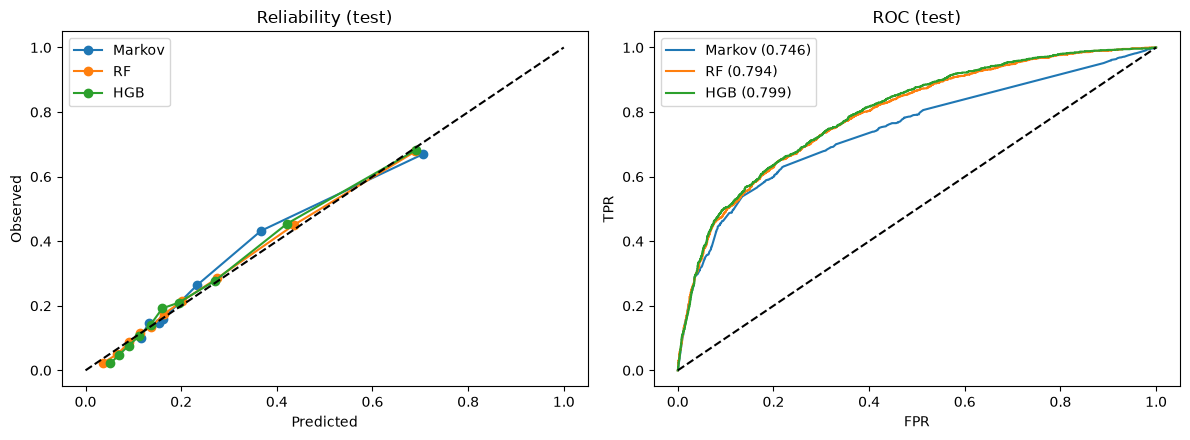

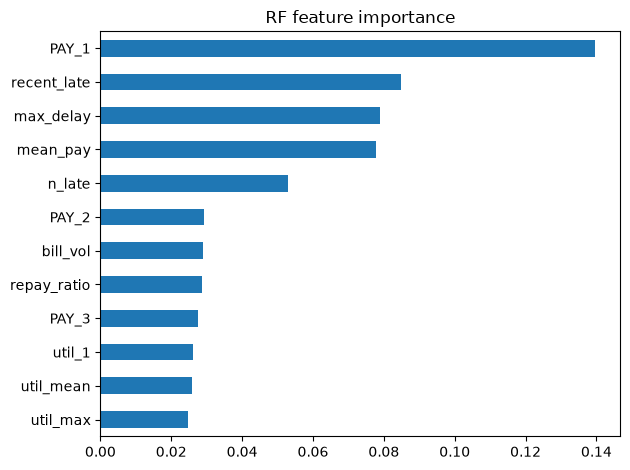

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, accuracy_score, confusion_matrix, brier_score_loss,
                             recall_score, precision_score, roc_curve)

ROOT = Path.cwd().parent
train      = pd.read_csv(ROOT / "data" / "processed" / "taiwan-train.csv", index_col="ID")
validation = pd.read_csv(ROOT / "data" / "processed" / "taiwan-validation.csv", index_col="ID")
test       = pd.read_csv(ROOT / "data" / "processed" / "taiwan-test.csv", index_col="ID")

TARGET = "default payment next month"
pay_cols  = [f"PAY_{i}" for i in range(6, 0, -1)]          # chronological Apr..Sep
bill_cols = [f"BILL_AMT{i}" for i in range(6, 0, -1)]
amt_cols  = [f"PAY_AMT{i}" for i in range(6, 0, -1)]

y_tr, y_va, y_te = train[TARGET].values, validation[TARGET].values, test[TARGET].values
print({k: (len(d), round(d[TARGET].mean(), 3)) for k, d in
       [("train", train), ("val", validation), ("test", test)]})

# =========================================================
# 1. Markov chain model
# =========================================================
K = 5
def to_state(p):
    p = np.asarray(p); s = np.empty(p.shape, dtype=int)
    s[p == -2] = 0; s[p == -1] = 1; s[p == 0] = 2; s[p == 1] = 3; s[p >= 2] = 4
    return s

S_tr, S_va, S_te = (to_state(d[pay_cols].values) for d in (train, validation, test))

def fit_chain(S, alpha=1.0):
    init = np.bincount(S[:, 0], minlength=K) + alpha; init = init / init.sum()
    C = np.zeros((K, K)) + alpha
    for a, b in zip(S[:, :-1].ravel(), S[:, 1:].ravel()): C[a, b] += 1
    return init, C / C.sum(axis=1, keepdims=True)

init0, P0 = fit_chain(S_tr[y_tr == 0])                     # fitted on TRAIN only
init1, P1 = fit_chain(S_tr[y_tr == 1])
log_prior = np.log(y_tr.mean() / (1 - y_tr.mean()))

def llr(S):
    sc = np.log(init1[S[:, 0]]) - np.log(init0[S[:, 0]])
    for t in range(S.shape[1] - 1):
        sc += np.log(P1[S[:, t], S[:, t+1]]) - np.log(P0[S[:, t], S[:, t+1]])
    return sc + log_prior

sc_tr, sc_va, sc_te = llr(S_tr), llr(S_va), llr(S_te)

# Platt calibration fitted on VALIDATION scores
platt = LogisticRegression(C=1e6).fit(sc_va.reshape(-1, 1), y_va)
p_mk_va = platt.predict_proba(sc_va.reshape(-1, 1))[:, 1]
p_mk_te = platt.predict_proba(sc_te.reshape(-1, 1))[:, 1]

# =========================================================
# 2. Random forest (+ optional gradient boosting)
# =========================================================
def make_features(d):
    X = d.drop(columns=TARGET).copy(); L = X["LIMIT_BAL"]
    B, A = X[bill_cols].values, X[amt_cols].values
    X["n_late"]      = (X[pay_cols] > 0).sum(axis=1)
    X["max_delay"]   = X[pay_cols].max(axis=1)
    X["mean_pay"]    = X[pay_cols].mean(axis=1)
    X["recent_late"] = (X[["PAY_1", "PAY_2"]] > 0).sum(axis=1)
    X["n_revolve"]   = (X[pay_cols] == 0).sum(axis=1)
    X["pay_slope"]   = X["PAY_1"] - X["PAY_6"]
    X["util_1"]      = B[:, -1] / L
    X["util_mean"]   = B.mean(axis=1) / L
    X["util_max"]    = B.max(axis=1) / L
    X["bill_trend"]  = (B[:, -1] - B[:, 0]) / L
    X["repay_ratio"] = A.sum(axis=1) / (np.clip(B, 0, None).sum(axis=1) + 1)
    X["zero_pay_n"]  = (A == 0).sum(axis=1)
    X["bill_vol"]    = B.std(axis=1) / (np.abs(B).mean(axis=1) + 1)
    return X

X_tr, X_va, X_te = make_features(train), make_features(validation), make_features(test)

models = {
    "RF": RandomForestClassifier(n_estimators=400, min_samples_leaf=20, n_jobs=-1, random_state=42),
    "HGB": HistGradientBoostingClassifier(learning_rate=0.05, max_depth=4, max_iter=200,
                                          l2_regularization=1, random_state=42),
}
for m in models.values(): m.fit(X_tr, y_tr)

# =========================================================
# 3. Model selection on VALIDATION (threshold also from validation)
# =========================================================
val_probs  = {"Markov": p_mk_va, **{k: m.predict_proba(X_va)[:, 1] for k, m in models.items()}}
test_probs = {"Markov": p_mk_te, **{k: m.predict_proba(X_te)[:, 1] for k, m in models.items()}}

base_va = brier_score_loss(y_va, np.full(len(y_va), y_tr.mean()))
print("\nVALIDATION")
for k, p in val_probs.items():
    print(f"{k:7s} AUC {roc_auc_score(y_va, p):.4f}  Brier {brier_score_loss(y_va, p):.4f}")
print(f"baseline Brier {base_va:.4f}")

# =========================================================
# 4. Final TEST evaluation (touch once)
# =========================================================
base_te = brier_score_loss(y_te, np.full(len(y_te), y_tr.mean()))
rows = []
for k in test_probs:
    f, t, th = roc_curve(y_va, val_probs[k])
    thr = th[np.argmax(t - f)]                              # Youden threshold from VALIDATION
    pred = (test_probs[k] > thr).astype(int)
    bs = brier_score_loss(y_te, test_probs[k])
    rows.append(dict(model=k, AUC=roc_auc_score(y_te, test_probs[k]), Brier=bs,
                     BSS=1 - bs / base_te, threshold=thr,
                     accuracy=accuracy_score(y_te, pred),
                     recall=recall_score(y_te, pred), precision=precision_score(y_te, pred)))
results = pd.DataFrame(rows).set_index("model").round(4)
print("\nTEST\n", results, f"\nbaseline Brier {base_te:.4f}")

# diagnostics on test
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for k, p in test_probs.items():
    fp, mp = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
    ax[0].plot(mp, fp, "o-", label=k)
    f, t, _ = roc_curve(y_te, p); ax[1].plot(f, t, label=f"{k} ({roc_auc_score(y_te, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set_title("Reliability (test)")
ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Observed"); ax[0].legend()
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set_title("ROC (test)")
ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR"); ax[1].legend()
plt.tight_layout(); plt.show()

imp = pd.Series(models["RF"].feature_importances_, X_tr.columns).sort_values()
imp.tail(12).plot.barh(title="RF feature importance"); plt.tight_layout(); plt.show()